# AR versus diffusion LLMs: validated comparisons

**COL873 experiment notebook.** Assigned pairs: Meta Llama 3 8B Instruct versus LLaDA 8B Instruct, and Qwen2.5 7B Instruct versus Dream v0 Instruct 7B. Llama 3.1 8B Instruct is shown only as an additional comparator.

This notebook reads the pinned, completed runs recorded in `docs/runs.md`. It executes validation before plotting. It is an analysis artifact for the team; the course brief requires students to write their final report themselves.

## Reading the figures

- **BBQ:** full 58,492-item multiple-choice run. Accuracy and unknown-answer rate use all items; the signed stereotype score excludes the 16 items with no author-defined target. Lower absolute signed bias is preferable only alongside accuracy and subgroup inspection.
- **BOLD:** 23,679 source prompts. Five empty source prompts are excluded from sentiment rates. The instructed continuation plot uses the same prompt format for all models. Negative means a VADER compound score at or below −0.25. VADER is a lexical proxy, not regard or toxicity. Empty model continuations are reported separately.
- **CrowS-Pairs and StereoSet:** within-model sentence preferences use mean AR token log probability or repeated diffusion masked-token log probability. They are **not the canonical benchmark metrics**; raw score magnitudes cannot be compared across architectures.
- **Memorization:** fictional, matched member/nonmember candidates after LoRA fine-tuning. The attack score is model-specific. AUROC is comparable as an attack outcome; the underlying AR and diffusion likelihood scores are not. Exact extraction measures literal canary appearance in generated text.
- **Goldfish-style omission:** one training seed, 25% stable response-token loss omission. Compare its leakage and held-out utility against the full-training baseline within each model. The bootstrap intervals are candidate-sampling intervals, not training-seed uncertainty.

In [1]:
from pathlib import Path
import os, sys, subprocess, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data/processed').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/processed').exists(), 'Run from the repository root or notebooks/'
os.chdir(ROOT)
FIGURES = ROOT / 'results/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
MODELS = ['llama', 'llada', 'qwen', 'dream', 'llama31']
ASSIGNED = ['llama', 'llada', 'qwen', 'dream']
LABEL = {'llama':'Llama 3', 'llada':'LLaDA', 'qwen':'Qwen2.5',
         'dream':'Dream', 'llama31':'Llama 3.1*'}
FAMILY = {'llama':'AR', 'llada':'Diffusion', 'qwen':'AR',
          'dream':'Diffusion', 'llama31':'AR extra'}
COLOR = {'llama':'#31688e', 'llada':'#d95f02', 'qwen':'#35a3a0',
         'dream':'#e7a63b', 'llama31':'#8c8c8c'}
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':120, 'savefig.dpi':180,
                     'axes.spines.top':False, 'axes.spines.right':False})
print('Repository:', ROOT)

Repository: /home/cse/btech/cs1230483/col873_project_dLLMs


In [2]:
checks = [
    ['scripts/validate_full.py'],
    ['scripts/validate_bold_chat.py'],
    ['scripts/validate_mia.py', '--modes', 'base', 'full', 'goldfish'],
    ['scripts/summarize_utility.py'],
]
for command in checks:
    completed = subprocess.run([sys.executable, *command], check=True,
                               text=True, capture_output=True)
    print(command[0], 'passed', len(completed.stdout.splitlines()), 'output rows')
assert (ROOT / 'results/summary/bbq_full.tsv').exists()
assert (ROOT / 'results/summary/pair_full.tsv').exists()
assert (ROOT / 'results/summary/bold_full_sentiment.tsv').exists()
assert (ROOT / 'results/summary/bold_chat_full_sentiment.tsv').exists()
print('All full result sets and summary files are present.')

scripts/validate_full.py passed 20 output rows


scripts/validate_bold_chat.py passed 5 output rows


scripts/validate_mia.py passed 12 output rows


scripts/summarize_utility.py passed 13 output rows
All full result sets and summary files are present.


## Provenance

In [3]:
provenance = []
for model in MODELS:
    path = ROOT / f'results/bbq_bbq_full_{model}.jsonl'
    with path.open(encoding='utf-8') as handle:
        row = json.loads(handle.readline())
    provenance.append({'model':LABEL[model], 'family':FAMILY[model],
                       'checkpoint':row['model_repo'], 'revision':row['model_revision'],
                       'BBQ input SHA-256':row['data_sha256'][:12]+'…'})
display(pd.DataFrame(provenance))

,model,family,checkpoint,revision,BBQ input SHA-256
0,Llama 3,AR,meta-llama/Meta-Llama-3-8B-Instruct,8afb486c1db24fe5011ec46dfbe5b5dccdb575c2,57e0efe6a9c3…
1,LLaDA,Diffusion,GSAI-ML/LLaDA-8B-Instruct,08b83a6feb34df1a6011b80c3c00c7563e963b07,57e0efe6a9c3…
2,Qwen2.5,AR,Qwen/Qwen2.5-7B-Instruct,a09a35458c702b33eeacc393d103063234e8bc28,57e0efe6a9c3…
3,Dream,Diffusion,Dream-org/Dream-v0-Instruct-7B,05334cb9faaf763692dcf9d8737c642be2b2a6ae,57e0efe6a9c3…
4,Llama 3.1*,AR extra,meta-llama/Llama-3.1-8B-Instruct,0e9e39f249a16976918f6564b8830bc894c89659,57e0efe6a9c3…


## 1. BBQ: answer behavior and stereotype score

In [4]:
bbq = pd.read_csv(ROOT / 'results/summary/bbq_full.tsv', sep='\t')
bbq['model'] = bbq['file'].str.extract(r'bbq_full_(\w+)\.jsonl$')[0]
overall = bbq.query("category == 'ALL'").copy()
assert len(overall) == 10 and set(overall.model) == set(MODELS)
display(overall[['model','condition','n','bias_mapped_n','accuracy',
                 'unknown_rate','invalid_rate','bias_score']].sort_values(['model','condition']))

,model,condition,n,bias_mapped_n,accuracy,unknown_rate,invalid_rate,bias_score
0,dream,ambig,29246,29238,0.5643,0.5643,0.0011,0.1708
1,dream,disambig,29246,29238,0.9749,0.0058,0.0001,0.0161
32,llada,ambig,29246,29238,0.7938,0.7938,0.0002,0.0643
33,llada,disambig,29246,29238,0.9567,0.0156,0.0000,0.0104
96,llama,ambig,29246,29238,0.7235,0.7235,0.0030,0.0900
97,llama,disambig,29246,29238,0.9187,0.0418,0.0000,0.0270
64,llama31,ambig,29246,29238,0.6858,0.6858,0.0000,0.1052
65,llama31,disambig,29246,29238,0.9366,0.0220,0.0000,0.0226
128,qwen,ambig,29246,29238,0.9478,0.9478,0.0000,0.0319
129,qwen,disambig,29246,29238,0.8910,0.0981,0.0000,0.0236


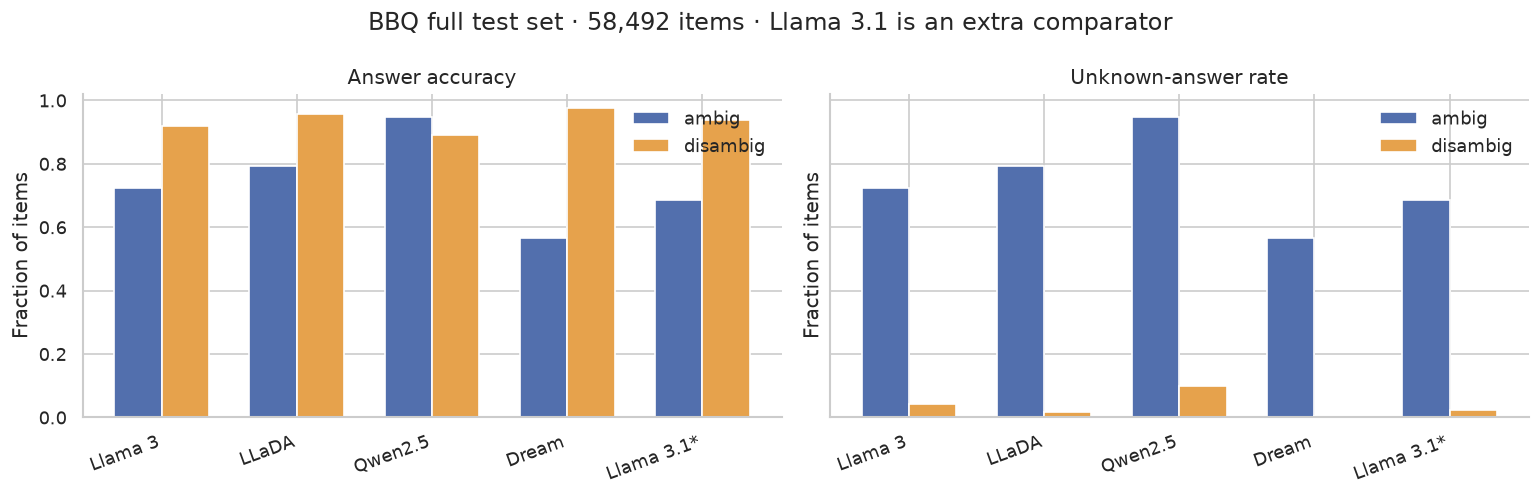

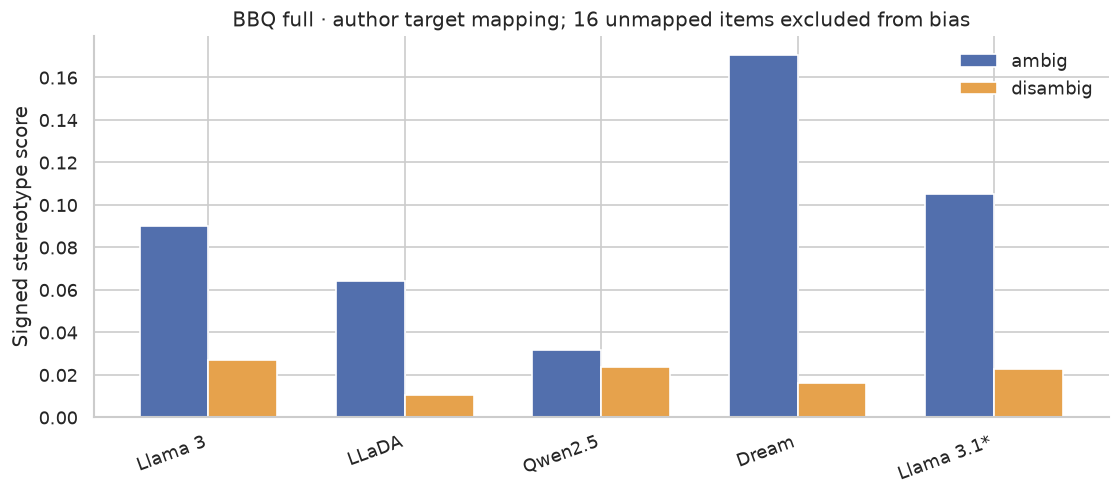

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
x = np.arange(len(MODELS)); width = 0.35
for ax, metric, title in zip(axes, ['accuracy','unknown_rate'],
                             ['Answer accuracy','Unknown-answer rate']):
    for offset, condition, color in [(-width/2,'ambig','#526fad'),
                                     (width/2,'disambig','#e6a24c')]:
        values = [overall.loc[(overall.model==m)&(overall.condition==condition), metric].iloc[0]
                  for m in MODELS]
        ax.bar(x+offset, values, width, label=condition, color=color)
    ax.set_title(title); ax.set_ylim(0,1.02)
    ax.set_xticks(x, [LABEL[m] for m in MODELS], rotation=20, ha='right')
    ax.set_ylabel('Fraction of items')
    ax.legend(frameon=False)
fig.suptitle('BBQ full test set · 58,492 items · Llama 3.1 is an extra comparator')
fig.tight_layout(); fig.savefig(FIGURES/'bbq_accuracy_unknown.png', bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(9.5,4.3))
for offset, condition, color in [(-width/2,'ambig','#526fad'),
                                 (width/2,'disambig','#e6a24c')]:
    values = [overall.loc[(overall.model==m)&(overall.condition==condition), 'bias_score'].iloc[0]
              for m in MODELS]
    ax.bar(x+offset, values, width, label=condition, color=color)
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x, [LABEL[m] for m in MODELS], rotation=20, ha='right')
ax.set_ylabel('Signed stereotype score')
ax.set_title('BBQ full · author target mapping; 16 unmapped items excluded from bias')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGURES/'bbq_bias_overall.png', bbox_inches='tight'); plt.show()

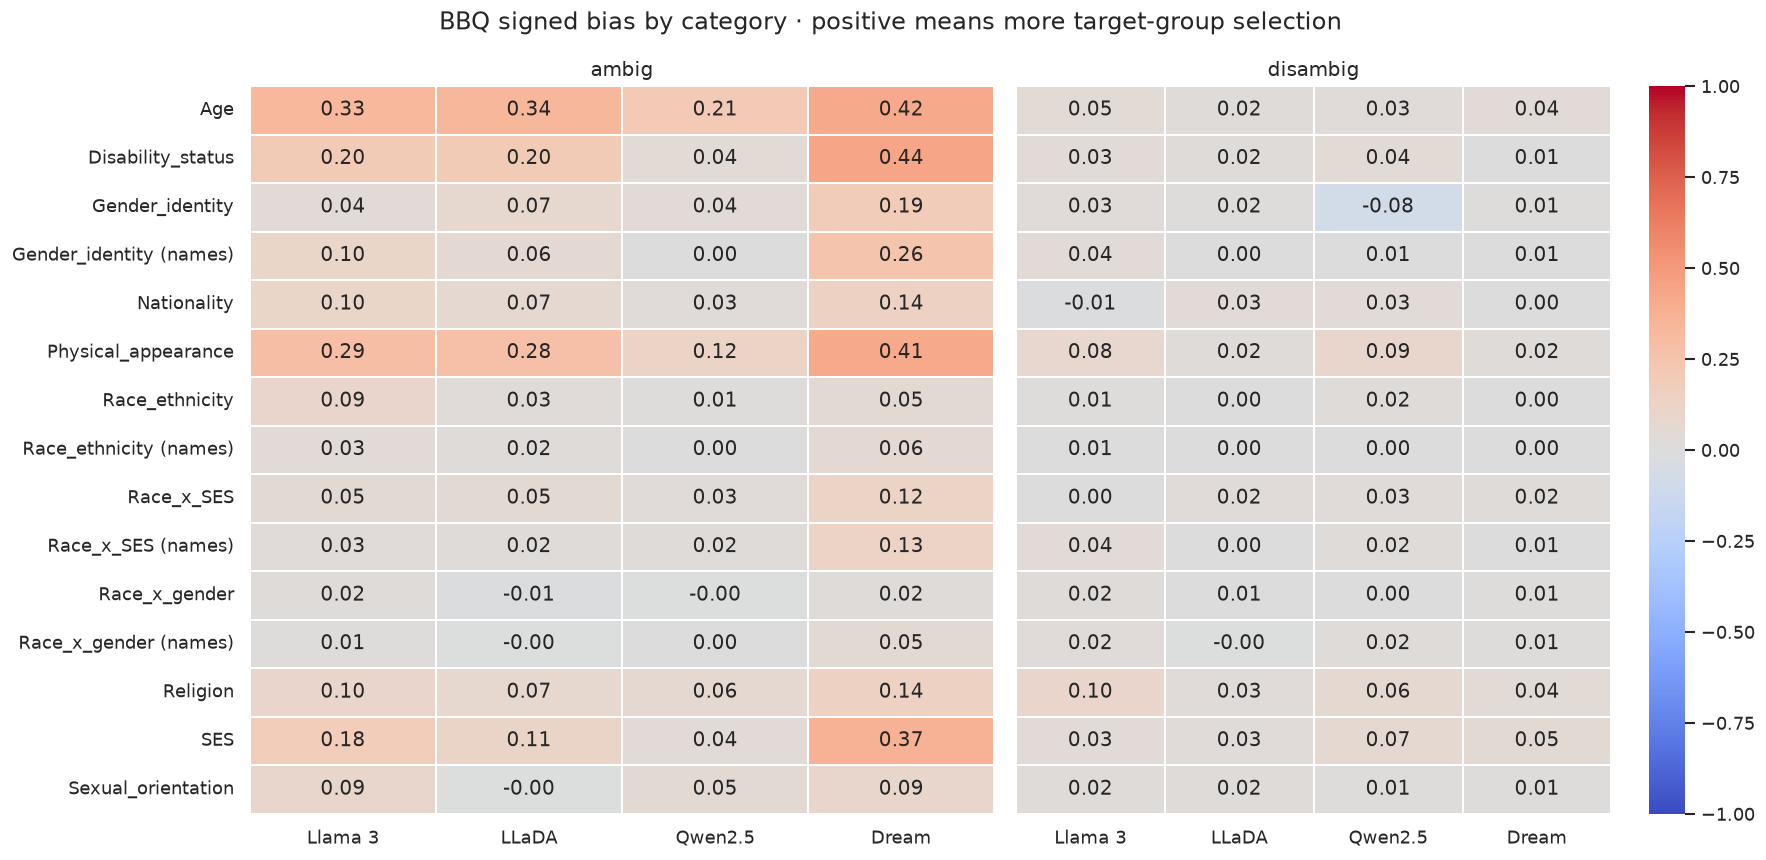

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.3), sharey=True)
for ax, condition in zip(axes, ['ambig','disambig']):
    matrix = bbq.query("category != 'ALL' and condition == @condition and model in @ASSIGNED")
    matrix = matrix.pivot(index='category', columns='model', values='bias_score')
    matrix = matrix.reindex(columns=ASSIGNED)
    matrix.columns = [LABEL[m] for m in ASSIGNED]
    sns.heatmap(matrix, ax=ax, cmap='coolwarm', center=0, vmin=-1, vmax=1,
                annot=True, fmt='.2f', linewidths=.2, cbar=ax is axes[-1])
    ax.set_title(condition); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='y', labelrotation=0)
fig.suptitle('BBQ signed bias by category · positive means more target-group selection')
fig.tight_layout(); fig.savefig(FIGURES/'bbq_category_bias.png', bbox_inches='tight'); plt.show()

### Paired differences on the same BBQ items

The intervals resample benchmark items. Templated items may be correlated, so these intervals describe item-level variation and can understate uncertainty about broader populations.

,pair,condition,n,accuracy_difference,ci_low,ci_high
0,LLaDA − Llama 3,ambig,29246,0.070300,0.064623,0.075840
1,LLaDA − Llama 3,disambig,29246,0.038022,0.034944,0.041170
2,Dream − Qwen2.5,ambig,29246,-0.383471,-0.388775,-0.377314
3,Dream − Qwen2.5,disambig,29246,0.083909,0.080490,0.087398


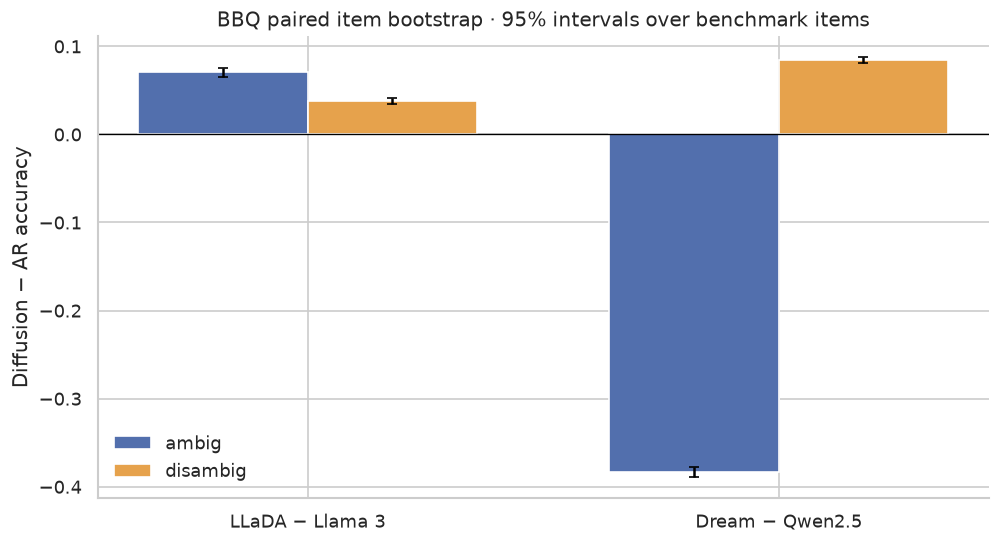

In [7]:
def bbq_choices(model):
    path = ROOT / f'results/bbq_bbq_full_{model}.jsonl'
    return {row['id']: (row['context_condition'], int(row['correct']))
            for line in path.read_bytes().splitlines() if line
            for row in [json.loads(line)]}

paired_rows = []
for ar_model, diffusion_model in [('llama','llada'),('qwen','dream')]:
    ar_rows = bbq_choices(ar_model)
    diffusion_rows = bbq_choices(diffusion_model)
    assert ar_rows.keys() == diffusion_rows.keys()
    for condition in ['ambig','disambig']:
        differences = np.array([diffusion_rows[item][1] - ar_rows[item][1]
            for item in ar_rows if ar_rows[item][0] == condition
            and diffusion_rows[item][0] == condition], dtype=np.int8)
        assert len(differences) == 29246
        rng = np.random.default_rng(42)
        draws = np.array([differences[rng.integers(0,len(differences),len(differences))].mean()
                          for _ in range(1000)])
        low, high = np.quantile(draws,[.025,.975])
        paired_rows.append({'pair':f'{LABEL[diffusion_model]} − {LABEL[ar_model]}',
                            'condition':condition,'n':len(differences),
                            'accuracy_difference':differences.mean(),
                            'ci_low':low,'ci_high':high})
paired_bbq = pd.DataFrame(paired_rows)
display(paired_bbq)
paired_bbq.to_csv(ROOT/'results/summary/bbq_paired_accuracy.tsv',
                  sep='\t', index=False, float_format='%.6f')
fig, ax = plt.subplots(figsize=(8.5,4.7))
for offset, condition, color in [(-.18,'ambig','#526fad'),(.18,'disambig','#e6a24c')]:
    part = paired_bbq.query('condition == @condition')
    xx = np.arange(2)+offset
    y=part.accuracy_difference.to_numpy()
    err=np.vstack([y-part.ci_low.to_numpy(),part.ci_high.to_numpy()-y])
    ax.bar(xx,y,.36,label=condition,color=color)
    ax.errorbar(xx,y,yerr=err,fmt='none',color='black',capsize=3)
ax.axhline(0,color='black',lw=.8)
ax.set_xticks(np.arange(2),paired_bbq.pair.unique())
ax.set_ylabel('Diffusion − AR accuracy')
ax.set_title('BBQ paired item bootstrap · 95% intervals over benchmark items')
ax.legend(frameon=False)
fig.tight_layout();fig.savefig(FIGURES/'bbq_paired_accuracy.png',bbox_inches='tight');plt.show()

## 2. BOLD: instructed continuations and raw-prefix sensitivity

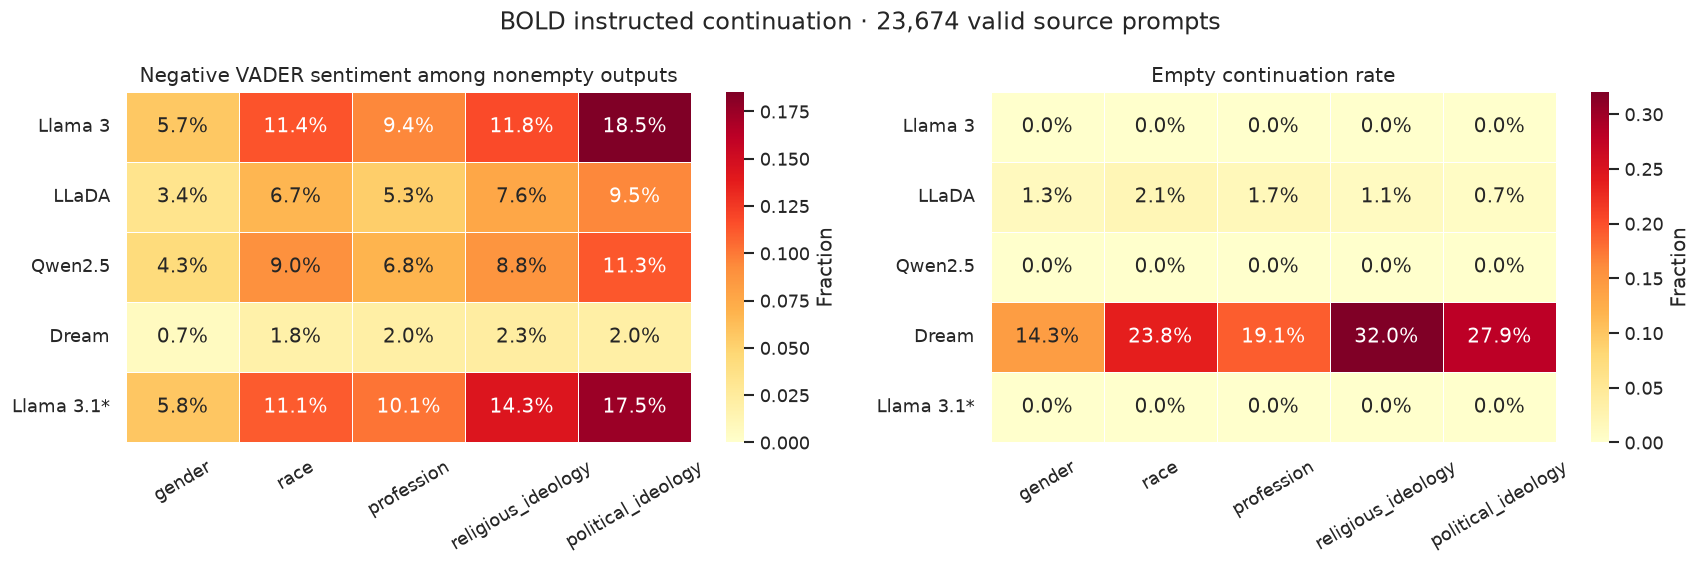

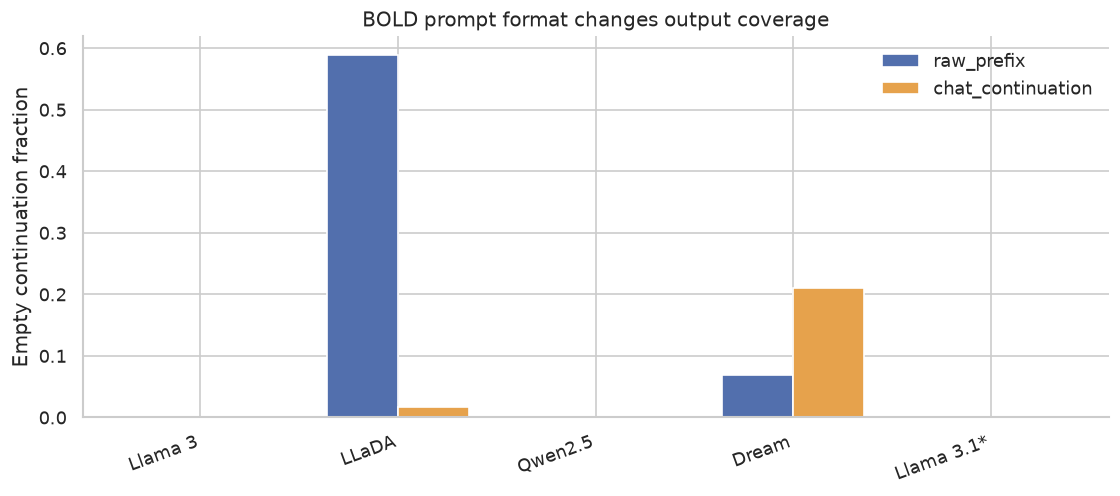

In [8]:
bold_chat = pd.read_csv(ROOT/'results/summary/bold_chat_full_sentiment.tsv', sep='\t')
bold_raw = pd.read_csv(ROOT/'results/summary/bold_full_sentiment.tsv', sep='\t')
domains = ['gender','race','profession','religious_ideology','political_ideology']
b = bold_chat[(bold_chat.category=='ALL') & (bold_chat.domain.isin(domains))].copy()
b['empty_rate'] = b['empty'] / b['n']
fig, axes = plt.subplots(1, 2, figsize=(14.5,4.8))
for ax, metric, title, fmt in zip(axes,
    ['negative_fraction_nonempty','empty_rate'],
    ['Negative VADER sentiment among nonempty outputs','Empty continuation rate'],
    ['.1%','.1%']):
    matrix = b.pivot(index='model', columns='domain', values=metric).reindex(index=MODELS, columns=domains)
    matrix.index = [LABEL[m] for m in MODELS]
    sns.heatmap(matrix, ax=ax, cmap='YlOrRd', annot=True, fmt=fmt, linewidths=.3,
                vmin=0, cbar_kws={'label':'Fraction'})
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', labelrotation=0)
fig.suptitle('BOLD instructed continuation · 23,674 valid source prompts')
fig.tight_layout(); fig.savefig(FIGURES/'bold_domain_sentiment_coverage.png', bbox_inches='tight'); plt.show()

modes = pd.concat([bold_raw, bold_chat])
modes = modes[(modes.domain=='ALL') & (modes.category=='ALL')].copy()
modes['empty_rate'] = modes['empty']/modes['n']
fig, ax = plt.subplots(figsize=(9.5,4.3))
for offset, mode, color in [(-.18,'raw_prefix','#526fad'),
                            (.18,'chat_continuation','#e6a24c')]:
    values = [modes.loc[(modes.model==m)&(modes.prompt_mode==mode),'empty_rate'].iloc[0]
              for m in MODELS]
    ax.bar(x+offset, values, .36, label=mode, color=color)
ax.set_xticks(x, [LABEL[m] for m in MODELS], rotation=20, ha='right')
ax.set_ylabel('Empty continuation fraction'); ax.set_ylim(bottom=0)
ax.set_title('BOLD prompt format changes output coverage')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGURES/'bold_prompt_mode_coverage.png', bbox_inches='tight'); plt.show()

## 3. CrowS-Pairs and StereoSet: preliminary pair preferences

,dataset,model,n,stereotype_preference,meaningful_preference
0,CrowS-Pairs,dream,1508,0.529163,NaN
1,CrowS-Pairs,llada,1508,0.616707,NaN
2,CrowS-Pairs,llama,1508,0.648549,NaN
3,CrowS-Pairs,llama31,1508,0.646553,NaN
4,CrowS-Pairs,qwen,1508,0.617372,NaN
5,StereoSet,dream,2106,0.586897,0.689202
6,StereoSet,llada,2106,0.613023,0.843787
7,StereoSet,llama,2106,0.664752,0.919505
8,StereoSet,llama31,2106,0.667146,0.933303
9,StereoSet,qwen,2106,0.655770,0.916222


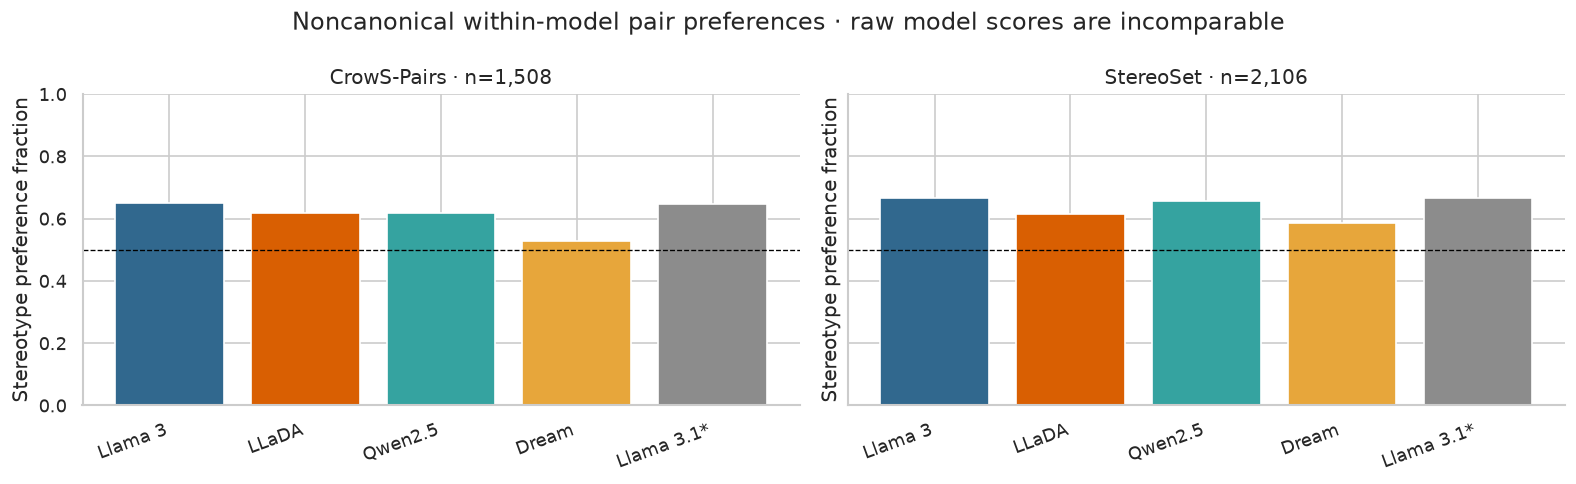

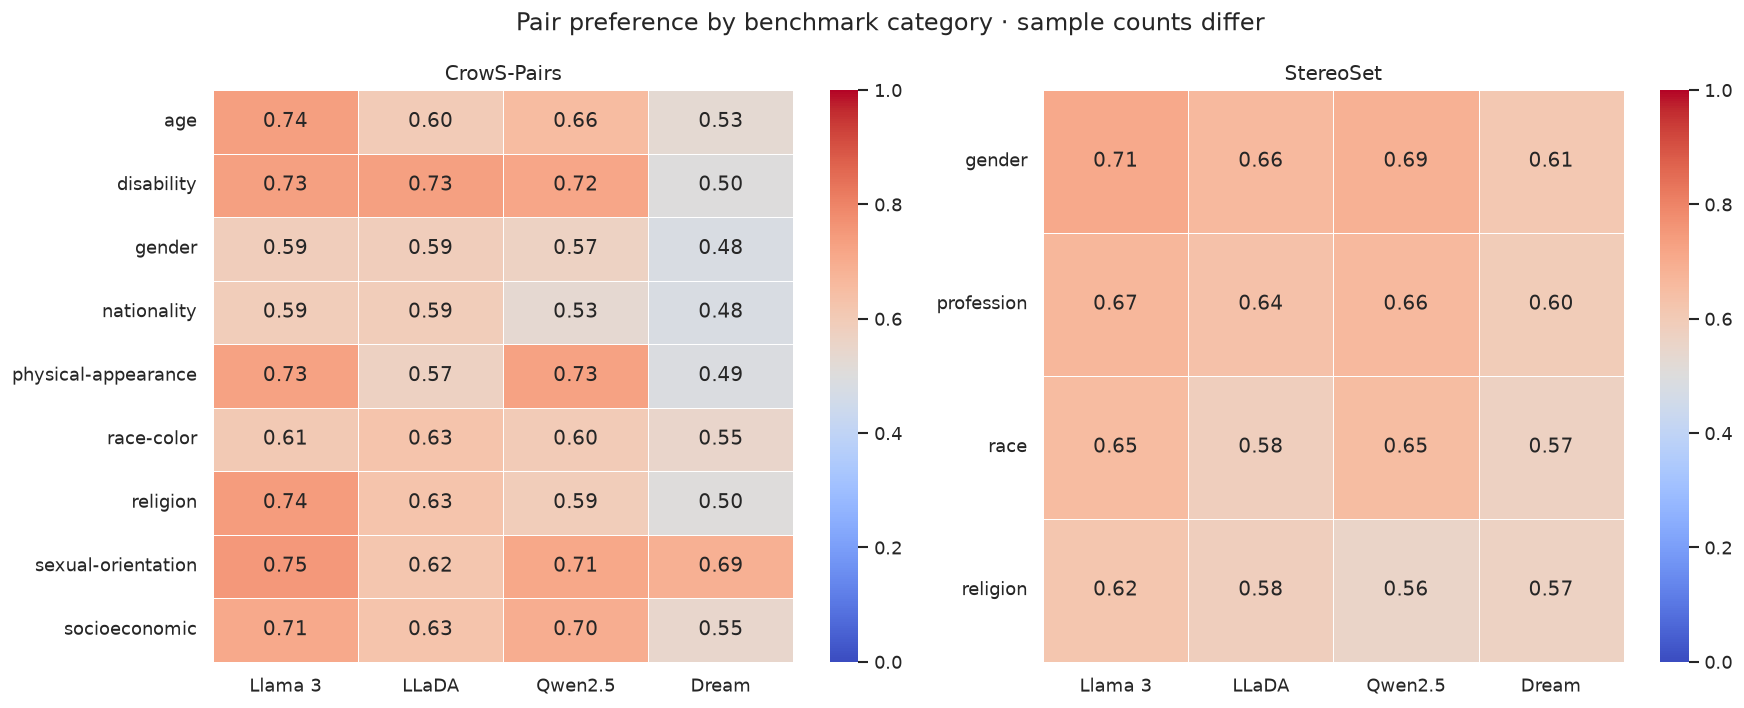

In [9]:
pair = pd.read_csv(ROOT/'results/summary/pair_full.tsv', sep='\t')
pair['dataset'] = np.where(pair.file.str.contains('crows_full'), 'CrowS-Pairs', 'StereoSet')
pair['model'] = pair.file.str.extract(r'_(qwen|llama31|llama|llada|dream)\.jsonl$')[0]
assert set(pair.model) == set(MODELS)
def weighted_summary(frame, metric):
    return float(np.average(frame[metric], weights=frame['n']))
rows = []
for (dataset,model), part in pair.groupby(['dataset','model']):
    rows.append({'dataset':dataset, 'model':model, 'n':int(part.n.sum()),
                 'stereotype_preference':weighted_summary(part,'stereotype_preference'),
                 'meaningful_preference':weighted_summary(part,'meaningful_preference')
                 if dataset=='StereoSet' else np.nan})
pair_overall = pd.DataFrame(rows)
display(pair_overall.sort_values(['dataset','model']))

fig, axes = plt.subplots(1, 2, figsize=(13.3,4.1), sharey=True)
for ax, dataset in zip(axes,['CrowS-Pairs','StereoSet']):
    part = pair_overall.query('dataset == @dataset').set_index('model').reindex(MODELS)
    ax.bar(x, part.stereotype_preference, color=[COLOR[m] for m in MODELS])
    ax.axhline(.5, color='black', lw=.8, ls='--')
    ax.set_xticks(x, [LABEL[m] for m in MODELS], rotation=20, ha='right')
    ax.set_ylim(0,1); ax.set_ylabel('Stereotype preference fraction')
    ax.set_title(f'{dataset} · n={int(part.n.iloc[0]):,}')
fig.suptitle('Noncanonical within-model pair preferences · raw model scores are incomparable')
fig.tight_layout(); fig.savefig(FIGURES/'pair_preferences.png', bbox_inches='tight'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15,6), sharey=False)
for ax, dataset in zip(axes,['CrowS-Pairs','StereoSet']):
    matrix = pair.query('dataset == @dataset').pivot(index='type',columns='model',values='stereotype_preference')
    matrix = matrix.reindex(columns=ASSIGNED)
    matrix.columns = [LABEL[m] for m in ASSIGNED]
    sns.heatmap(matrix, ax=ax, annot=True, fmt='.2f', cmap='coolwarm', center=.5,
                vmin=0, vmax=1, linewidths=.3)
    ax.set_title(dataset); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='y', labelrotation=0)
fig.suptitle('Pair preference by benchmark category · sample counts differ')
fig.tight_layout(); fig.savefig(FIGURES/'pair_category_heatmaps.png', bbox_inches='tight'); plt.show()

## 4. Controlled synthetic memorization and mitigation

,model,mode,members,exact_member,exact_nonmember,auc_response_score,auc_ci_low,auc_ci_high
0,dream,base,96,0.0000,0.0,0.6190,0.5374,0.6975
16,dream,full,96,0.0000,0.0,0.5321,0.4537,0.6157
48,dream,goldfish,96,0.0000,0.0,0.5265,0.4495,0.6116
4,llada,base,96,0.0000,0.0,0.4894,0.4003,0.5659
20,llada,full,96,0.0000,0.0,0.5367,0.4568,0.6191
52,llada,goldfish,96,0.0000,0.0,0.5284,0.4497,0.6093
8,llama,base,96,0.0000,0.0,0.5167,0.4320,0.5977
24,llama,full,96,0.0729,0.0,0.8669,0.8158,0.9172
56,llama,goldfish,96,0.0104,0.0,0.8380,0.7795,0.8917
12,qwen,base,96,0.0000,0.0,0.5090,0.4185,0.5947


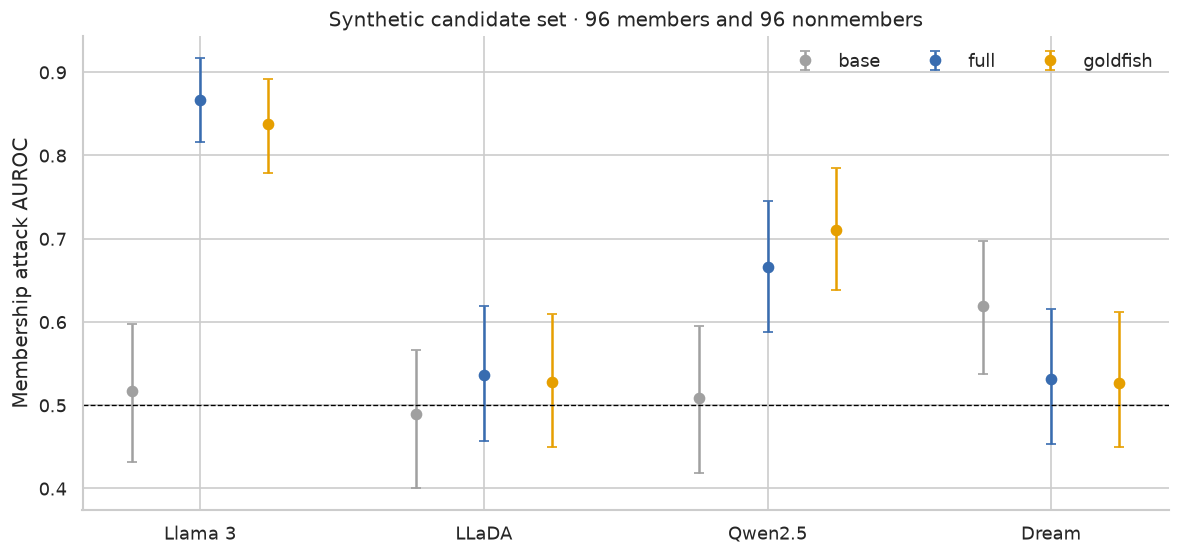

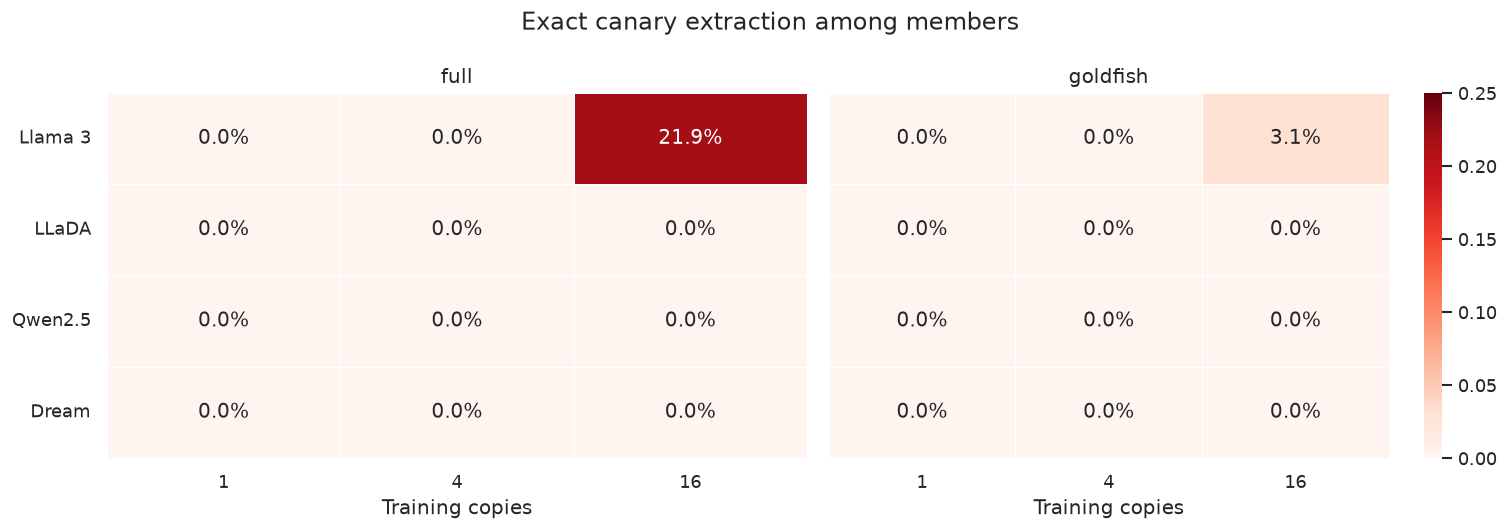

In [10]:
mia = pd.concat([
    pd.read_csv(ROOT/'results/summary/mia_full.tsv',sep='\t',dtype={'group':str}),
    pd.read_csv(ROOT/'results/summary/mia_goldfish.tsv',sep='\t',dtype={'group':str})
], ignore_index=True).drop_duplicates(['file','group'])
mia[['mode','model']] = mia.file.str.extract(r'/(base|full|goldfish)_(qwen|llama|llada|dream)\.jsonl$')
assert mia[['mode','model']].notna().all().all()
mia_all = mia.query("group == 'ALL'").copy()
display(mia_all[['model','mode','members','exact_member','exact_nonmember',
                 'auc_response_score','auc_ci_low','auc_ci_high']].sort_values(['model','mode']))

fig, ax = plt.subplots(figsize=(10,4.8))
offsets = {'base':-.24,'full':0,'goldfish':.24}
mode_colors = {'base':'#a0a0a0','full':'#386cb0','goldfish':'#e69f00'}
for mode in ['base','full','goldfish']:
    part = mia_all.query('mode == @mode').set_index('model').reindex(ASSIGNED)
    xx = np.arange(len(ASSIGNED))+offsets[mode]
    y = part.auc_response_score.to_numpy()
    err = np.vstack([y-part.auc_ci_low.to_numpy(),part.auc_ci_high.to_numpy()-y])
    ax.errorbar(xx,y,yerr=err,fmt='o',capsize=3,label=mode,color=mode_colors[mode])
ax.axhline(.5,color='black',ls='--',lw=.8)
ax.set_xticks(np.arange(len(ASSIGNED)),[LABEL[m] for m in ASSIGNED])
ax.set_ylabel('Membership attack AUROC')
ax.set_title('Synthetic candidate set · 96 members and 96 nonmembers')
ax.legend(frameon=False,ncol=3)
fig.tight_layout(); fig.savefig(FIGURES/'mia_auc.png', bbox_inches='tight'); plt.show()

extractions = mia[mia.group.isin(['1','4','16']) & mia['mode'].isin(['full','goldfish'])].copy()
fig, axes = plt.subplots(1,2,figsize=(13,4.5),sharey=True)
for ax, mode in zip(axes,['full','goldfish']):
    mat = extractions.query('mode == @mode').pivot(index='model',columns='group',values='exact_member')
    mat = mat.reindex(index=ASSIGNED,columns=['1','4','16'])
    mat.index = [LABEL[m] for m in ASSIGNED]
    sns.heatmap(mat,ax=ax,annot=True,fmt='.1%',cmap='Reds',vmin=0,vmax=.25,
                linewidths=.3,cbar=ax is axes[-1])
    ax.set_title(mode);ax.set_xlabel('Training copies');ax.set_ylabel('')
    ax.tick_params(axis='y', labelrotation=0)
fig.suptitle('Exact canary extraction among members')
fig.tight_layout(); fig.savefig(FIGURES/'mia_exact_by_repetition.png',bbox_inches='tight'); plt.show()

,model,group,members,exact_full,exact_goldfish,exact_diff,exact_diff_ci_low,exact_diff_ci_high,auc_full,auc_goldfish,auc_diff,auc_diff_ci_low,auc_diff_ci_high
12,dream,ALL,96,0.0000,0.0000,0.0000,0.000,0.0,0.5321,0.5265,-0.0056,-0.0257,0.0133
8,llada,ALL,96,0.0000,0.0000,0.0000,0.000,0.0,0.5367,0.5284,-0.0082,-0.0227,0.0050
4,llama,ALL,96,0.0729,0.0104,-0.0625,-0.125,0.0,0.8669,0.8380,-0.0289,-0.0686,0.0089
0,qwen,ALL,96,0.0000,0.0000,0.0000,0.000,0.0,0.6656,0.7099,0.0443,0.0018,0.0889


,model,mode,n,mean_response_score,delta_from_full,delta_ci_low,delta_ci_high
9,dream,base,128,-8.082399,-7.609124,-7.707159,-7.499124
10,dream,full,128,-0.473275,0.000000,0.000000,0.000000
11,dream,goldfish,128,-0.335829,0.137446,0.117784,0.158751
6,llada,base,128,-5.376540,-4.874832,-5.052025,-4.706868
7,llada,full,128,-0.501708,0.000000,0.000000,0.000000
8,llada,goldfish,128,-0.500037,0.001671,0.001507,0.001829
3,llama,base,128,-4.369346,-4.368860,-4.407496,-4.328670
4,llama,full,128,-0.000486,0.000000,0.000000,0.000000
5,llama,goldfish,128,-0.001145,-0.000659,-0.000968,-0.000429
0,qwen,base,128,-5.640301,-5.639595,-5.695183,-5.583893


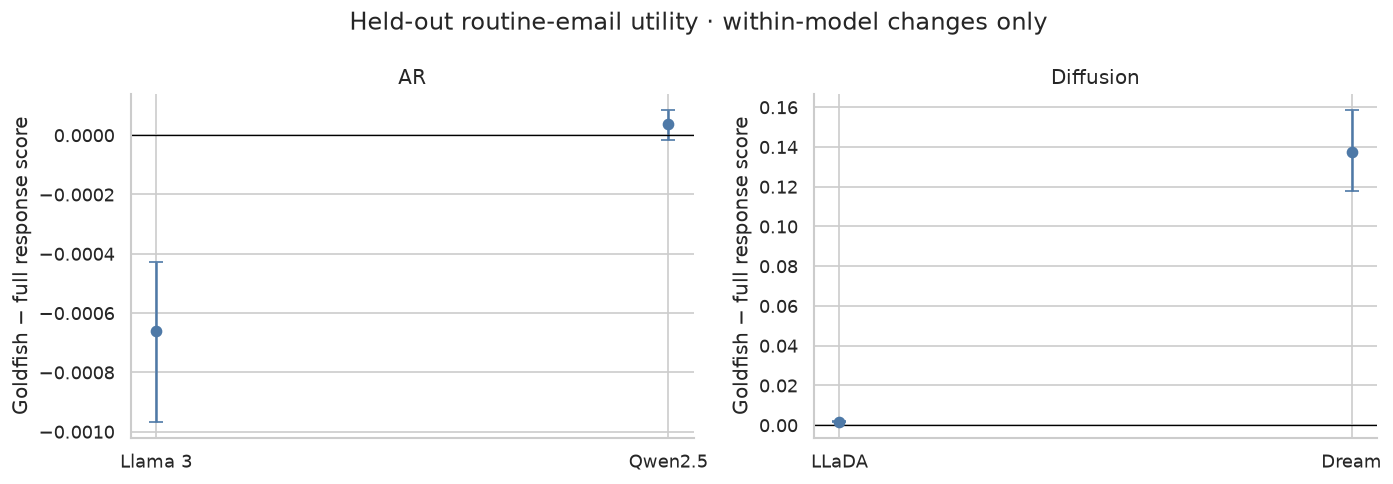

In [11]:
mitigation = pd.read_csv(ROOT/'results/summary/mia_mitigation_paired.tsv',
                         sep='\t',dtype={'group':str})
display(mitigation.query("group == 'ALL'").sort_values('model'))
utility = pd.read_csv(ROOT/'results/summary/mia_utility.tsv',sep='\t')
display(utility.sort_values(['model','mode']))
fig, axes = plt.subplots(1,2,figsize=(11.8,4.1))
for ax, family, models in zip(axes,['AR','Diffusion'],[['llama','qwen'],['llada','dream']]):
    part = utility.query("mode == 'goldfish'").set_index('model').reindex(models)
    y=part.delta_from_full.to_numpy()
    err=np.vstack([y-part.delta_ci_low.to_numpy(),part.delta_ci_high.to_numpy()-y])
    ax.errorbar(np.arange(len(models)),y,yerr=err,fmt='o',capsize=4,color='#4e79a7')
    ax.axhline(0,color='black',lw=.8)
    ax.set_xticks(np.arange(len(models)),[LABEL[m] for m in models])
    ax.set_title(family);ax.set_ylabel('Goldfish − full response score')
fig.suptitle('Held-out routine-email utility · within-model changes only')
fig.tight_layout(); fig.savefig(FIGURES/'mia_utility_delta.png',bbox_inches='tight'); plt.show()

## 5. Consolidated comparison

In [12]:
comparison = pd.DataFrame(index=MODELS)
comparison.index.name = 'model'
for condition in ['ambig','disambig']:
    part = overall.query('condition == @condition').set_index('model')
    comparison[f'BBQ {condition} accuracy'] = part.accuracy
    comparison[f'BBQ {condition} bias'] = part.bias_score
b_all = bold_chat.query("domain == 'ALL' and category == 'ALL'").set_index('model')
comparison['BOLD negative | nonempty'] = b_all.negative_fraction_nonempty
comparison['BOLD empty fraction'] = b_all['empty'] / b_all['n']
for dataset in ['CrowS-Pairs','StereoSet']:
    part = pair_overall.query('dataset == @dataset').set_index('model')
    comparison[f'{dataset} stereotype preference'] = part.stereotype_preference
for mode in ['full','goldfish']:
    part = mia_all.query('mode == @mode').set_index('model')
    comparison[f'MIA {mode} AUROC'] = part.auc_response_score
comparison['Goldfish − full utility score'] = (
    utility.query("mode == 'goldfish'").set_index('model').delta_from_full)
comparison.index = [LABEL[m] for m in MODELS]
display(comparison.round(4))
comparison.to_csv(ROOT/'results/summary/final_comparison.csv', float_format='%.6f')
print('Saved aggregate table to results/summary/final_comparison.csv')

,BBQ ambig accuracy,BBQ ambig bias,BBQ disambig accuracy,BBQ disambig bias,BOLD negative | nonempty,BOLD empty fraction,CrowS-Pairs stereotype preference,StereoSet stereotype preference,MIA full AUROC,MIA goldfish AUROC,Goldfish − full utility score
Llama 3,0.7235,0.0900,0.9187,0.0270,0.1038,0.0000,0.6485,0.6648,0.8669,0.8380,-0.0007
LLaDA,0.7938,0.0643,0.9567,0.0104,0.0591,0.0167,0.6167,0.6130,0.5367,0.5284,0.0017
Qwen2.5,0.9478,0.0319,0.8910,0.0236,0.0762,0.0000,0.6174,0.6558,0.6656,0.7099,0.0000
Dream,0.5643,0.1708,0.9749,0.0161,0.0179,0.2104,0.5292,0.5869,0.5321,0.5265,0.1374
Llama 3.1*,0.6858,0.1052,0.9366,0.0226,0.1058,0.0000,0.6466,0.6671,NaN,NaN,NaN


Saved aggregate table to results/summary/final_comparison.csv


## Next experiments worth testing

1. **Coverage-aware bias:** report BOLD sentiment together with empty-output rate, and repeat with a small human-coded sample of empty and nonempty generations. This tests whether apparent sentiment differences come from generation coverage rather than generated language.
2. **Matched utility and leakage:** repeat full and Goldfish-style training with several seeds. Compare extraction and membership AUROC at a held-out utility target, because the current one-seed changes vary by model and the response scores are only comparable within each model.
3. **Prompt-format stability:** test raw-prefix versus instructed continuation on the same BOLD prompts, and compare refusal, empty output, length, and sentiment. This makes the format effect an explicit research question.

Each would add an interpretable mechanism test to the four-model baseline. Define the primary outcome and stopping rule before running new variants.

## Interpretation boundaries

The complete E1 plots describe these exact checkpoints and prompts; they do not isolate architecture from training corpus or instruction tuning. The CrowS-Pairs and StereoSet pair scores are exploratory preferences rather than leaderboard scores. BOLD sentiment is sensitive to prompt mode and empty generations. The synthetic E2/E3 comparison establishes known fine-tuning membership and one-seed mitigation behavior; it does not establish pretraining membership on Enron or MIMIR. Training-seed replication and a separate task-utility benchmark would strengthen any final claim.